# 03 — Acoustic Feature Extraction and Preprocessing Analysis

**Aim.** Convert each RAVDESS recording into 39 numeric acoustic features used by notebooks `04–05`. All features are computed from mono 16 kHz audio with **leading/trailing trimming at `top_db=30`**. We separately quantify the impact on duration over **all 1,440 recordings**.


**v2 extension (sections 8–11):** controlled feature and trimming ablations, with separate versioned outputs. The original 39-feature baseline remains unchanged.


## 1. Load metadata and audio

In [ ]:
from pathlib import Path
import zipfile

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from google.colab import drive
from IPython.display import display
from tqdm.auto import tqdm

drive.mount('/content/drive')
PROJECT_DIR = Path('/content/drive/MyDrive/speech-emotion-recognition-project-d')
ZIP_PATH = PROJECT_DIR / 'data/Audio_Speech_Actors_01-24.zip'
EXTRACT_DIR = Path('/content/ravdess_speech')
OUTPUT_DIR = PROJECT_DIR / 'data/processed'
FIGURES_DIR = PROJECT_DIR / 'results/figures/03_features'
METADATA_PATH = OUTPUT_DIR / 'ravdess_metadata.csv'
FEATURES_PATH = OUTPUT_DIR / 'ravdess_features.csv'

assert METADATA_PATH.is_file(), 'Run notebook 01 before 03.'
metadata = pd.read_csv(METADATA_PATH).sort_values('relative_path').reset_index(drop=True)
if len(list(EXTRACT_DIR.rglob('*.wav'))) != 1440:
    assert ZIP_PATH.is_file(), ZIP_PATH
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as archive:
        archive.extractall(EXTRACT_DIR)
audio_files = sorted(EXTRACT_DIR.rglob('*.wav'))
assert len(audio_files) == len(metadata) == 1440
assert set(metadata.relative_path) == {str(p.relative_to(EXTRACT_DIR)) for p in audio_files}
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print('Recordings:', len(audio_files))

Mounted at /content/drive
Recordings: 1440


In [ ]:
PURPLE = "#B57EDC"
DARK_PURPLE = "#9461B5"
BLUE = "#2A52BE"

BOX_STYLE = {
    "color": PURPLE,
    "width": 0.6,
    "linewidth": 1.2,
    "boxprops": {"edgecolor": DARK_PURPLE},
    "whiskerprops": {"color": DARK_PURPLE},
    "capprops": {"color": DARK_PURPLE},
    "medianprops": {"color": "white", "linewidth": 2},
    "flierprops": {
        "marker": "o",
        "markersize": 4,
        "markerfacecolor": "white",
        "markeredgecolor": DARK_PURPLE
    }
}

def style_ax(ax, title, grid_axis="y"):
    ax.set_title(title, fontweight="bold", loc="left", pad=14)
    ax.grid(axis=grid_axis, linestyle="--", alpha=0.2)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", labelrotation=0)
    sns.despine(ax=ax)

## 2. Fixed preprocessing and feature schema

For each recording: mono resampling → trim quiet edges → extract **MFCC (26)**, **RMS/ZCR (4)**, **spectral centroid/bandwidth/rolloff (6)**, and **F0/voiced ratio (3)**. Mean/std summarization discards time-order information but supports simple classical ML models. **Do not fit normalization here**; `04` places `StandardScaler` inside each CV pipeline.

In [ ]:
TARGET_SR = 16000
N_MFCC = 13
N_FFT = 1024
HOP_LENGTH = 256

def extract_features(file_path, top_db=30):

    # 1. Load and resample audio
    y, sr = librosa.load(
        str(file_path),
        sr=TARGET_SR,
        mono=True
    )

    # 2. Trim leading/trailing silence
    if top_db is not None:
        y, _ = librosa.effects.trim(y, top_db=top_db)

    if len(y) == 0 or np.max(np.abs(y)) < 1e-6:
        raise ValueError(f"Empty or silent audio: {file_path}")

    features = {}

    # 3. MFCCs
    mfcc = librosa.feature.mfcc(
        y=y,
        sr=sr,
        n_mfcc=N_MFCC,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH
    )

    for i in range(N_MFCC):
        features[f"mfcc_{i+1:02d}_mean"] = float(
            np.mean(mfcc[i])
        )
        features[f"mfcc_{i+1:02d}_std"] = float(
            np.std(mfcc[i])
        )

    # 4. Spectral representation
    S = np.abs(librosa.stft(
        y,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH
    ))

    rms = librosa.feature.rms(
        y=y,
        frame_length=N_FFT,
        hop_length=HOP_LENGTH
    )[0]

    zcr = librosa.feature.zero_crossing_rate(
        y,
        frame_length=N_FFT,
        hop_length=HOP_LENGTH
    )[0]

    centroid = librosa.feature.spectral_centroid(
        S=S, sr=sr
    )[0]

    bandwidth = librosa.feature.spectral_bandwidth(
        S=S, sr=sr
    )[0]

    rolloff = librosa.feature.spectral_rolloff(
        S=S, sr=sr
    )[0]

    acoustic_features = {
        "rms": rms,
        "zcr": zcr,
        "spectral_centroid": centroid,
        "spectral_bandwidth": bandwidth,
        "spectral_rolloff": rolloff
    }

    for name, values in acoustic_features.items():
        features[f"{name}_mean"] = float(np.mean(values))
        features[f"{name}_std"] = float(np.std(values))

    # 5. Pitch estimation with pYIN
    f0, voiced_flag, _ = librosa.pyin(
        y,
        sr=sr,
        fmin=65,
        fmax=500,
        frame_length=2048,
        hop_length=512
    )

    voiced_f0 = f0[np.isfinite(f0)]

    features["f0_hz_mean"] = (
        float(np.mean(voiced_f0))
        if len(voiced_f0) else 0.0
    )

    features["f0_hz_std"] = (
        float(np.std(voiced_f0))
        if len(voiced_f0) else 0.0
    )

    features["voiced_ratio"] = float(
        np.mean(voiced_flag)
    )

    return features

In [ ]:
sample_features = extract_features(audio_files[0])
assert len(sample_features) == 39, len(sample_features)
print('Acoustic features:', len(sample_features))
display(pd.Series(sample_features, name='sample value').to_frame().head(15))

Acoustic features: 39


,sample value
mfcc_01_mean,-553.012146
mfcc_01_std,91.760216
mfcc_02_mean,112.334206
mfcc_02_std,54.808365
mfcc_03_mean,-8.179104
mfcc_03_std,25.868269
mfcc_04_mean,31.441160
mfcc_04_std,28.776423
mfcc_05_mean,4.154149
mfcc_05_std,24.134785


## 3. Extract all 1,440 files (checkpointed)

If `ravdess_features.csv` already exists, it is loaded instead of recomputing slow pYIN features. To deliberately change extraction parameters, first archive/remove the old CSV and checkpoint so stale features are not silently reused.

In [ ]:
CHECKPOINT_PATH = OUTPUT_DIR / "ravdess_features_checkpoint.csv"
FEATURES_PATH = OUTPUT_DIR / "ravdess_features.csv"

if FEATURES_PATH.exists():
    features_df = pd.read_csv(FEATURES_PATH)

else:
    if CHECKPOINT_PATH.exists():
        partial_df = pd.read_csv(CHECKPOINT_PATH)
        extracted_records = partial_df.to_dict("records")
    else:
        extracted_records = []

    completed = {
        row["relative_path"] for row in extracted_records
    }

    for row in tqdm(
        metadata.to_dict("records"),
        desc="Extracting features"
    ):
        relative_path = row["relative_path"]

        if relative_path in completed:
            continue

        file_path = EXTRACT_DIR / relative_path

        features = extract_features(file_path)

        extracted_records.append({
            **row,
            **features
        })

        completed.add(relative_path)

        # Checkpoint every 50 recordings
        if len(extracted_records) % 50 == 0:
            pd.DataFrame(extracted_records).to_csv(
                CHECKPOINT_PATH,
                index=False
            )

    features_df = (
        pd.DataFrame(extracted_records)
        .sort_values("relative_path")
        .reset_index(drop=True)
    )

    features_df.to_csv(
        FEATURES_PATH,
        index=False
    )

print("Feature extraction completed!")
print("Dataset shape:", features_df.shape)
display(features_df.head())

Feature extraction completed!
Dataset shape: (1440, 49)


,relative_path,emotion,emotion_id,actor_id,gender,intensity,statement,repetition,duration_sec,sample_rate,...,zcr_std,spectral_centroid_mean,spectral_centroid_std,spectral_bandwidth_mean,spectral_bandwidth_std,spectral_rolloff_mean,spectral_rolloff_std,f0_hz_mean,f0_hz_std,voiced_ratio
0,Actor_01/03-01-01-01-01-01-01.wav,neutral,1,1,male,1,1,1,3.303292,48000,...,0.081081,1476.530023,815.358421,1451.287504,420.731907,2728.268678,1512.247496,116.565329,16.295102,0.931818
1,Actor_01/03-01-01-01-01-02-01.wav,neutral,1,1,male,1,1,2,3.336667,48000,...,0.078682,1481.953157,815.397130,1465.496831,368.994360,2799.030172,1358.868466,119.982938,18.750951,0.954545
2,Actor_01/03-01-01-01-02-01-01.wav,neutral,1,1,male,1,2,1,3.269917,48000,...,0.136101,1552.170971,1069.680859,1409.280748,388.172357,2795.955882,1578.248490,117.189317,14.108447,0.860465
3,Actor_01/03-01-01-01-02-02-01.wav,neutral,1,1,male,1,2,2,3.169833,48000,...,0.131457,1579.491982,1077.171054,1456.215793,420.858857,2866.705247,1651.301947,115.126709,14.849055,1.000000
4,Actor_01/03-01-02-01-01-01-01.wav,calm,2,1,male,1,1,1,3.536854,48000,...,0.137781,1586.385402,1095.428716,1461.860007,431.374998,2818.416262,1730.894205,116.941045,17.056856,0.596154


In [ ]:
mfcc_columns = [
    c for c in features_df.columns
    if c.startswith("mfcc_")
]

extra_columns = [
    f"{name}_{stat}"
    for name in [
        "rms",
        "zcr",
        "spectral_centroid",
        "spectral_bandwidth",
        "spectral_rolloff"
    ]
    for stat in ["mean", "std"]
]

extra_columns += [
    "f0_hz_mean",
    "f0_hz_std",
    "voiced_ratio"
]

feature_columns = mfcc_columns + extra_columns

assert len(features_df) == 1440
assert len(mfcc_columns) == 26
assert len(feature_columns) == 39

X = features_df[feature_columns]
y = features_df["emotion"]
groups = features_df["actor_id"]

assert np.isfinite(X.to_numpy()).all()

print("Samples:", X.shape[0])
print("Features:", X.shape[1])
print("Emotion classes:", y.nunique())
print("Speakers:", groups.nunique())
print("Missing values:", X.isna().sum().sum())
print("Recordings without detected pitch:",
      (features_df["voiced_ratio"] == 0).sum())

display(X.head())

Samples: 1440
Features: 39
Emotion classes: 8
Speakers: 24
Missing values: 0
Recordings without detected pitch: 19


,mfcc_01_mean,mfcc_01_std,mfcc_02_mean,mfcc_02_std,mfcc_03_mean,mfcc_03_std,mfcc_04_mean,mfcc_04_std,mfcc_05_mean,mfcc_05_std,...,zcr_std,spectral_centroid_mean,spectral_centroid_std,spectral_bandwidth_mean,spectral_bandwidth_std,spectral_rolloff_mean,spectral_rolloff_std,f0_hz_mean,f0_hz_std,voiced_ratio
0,-553.012146,91.760216,112.334206,54.808365,-8.179104,25.868269,31.441156,28.776423,4.154149,24.134785,...,0.081081,1476.530023,815.358421,1451.287504,420.731907,2728.268678,1512.247496,116.565329,16.295102,0.931818
1,-545.875610,79.260422,104.972870,53.866646,-6.104701,24.239164,36.562870,25.560980,0.961902,25.255487,...,0.078682,1481.953157,815.397130,1465.496831,368.994360,2799.030172,1358.868466,119.982938,18.750951,0.954545
2,-535.771301,93.209991,109.400703,64.467407,-2.827749,37.050457,30.082226,22.499626,-1.282854,27.709442,...,0.136101,1552.170971,1069.680859,1409.280748,388.172357,2795.955882,1578.248490,117.189317,14.108447,0.860465
3,-537.724915,98.369995,103.655205,63.812473,2.892381,34.659149,31.527639,25.445089,1.851007,24.570477,...,0.131457,1579.491982,1077.171054,1456.215793,420.858857,2866.705247,1651.301947,115.126709,14.849055,1.000000
4,-602.949158,85.089836,104.258598,61.775631,1.821521,33.091736,30.672693,27.651220,4.226604,25.572002,...,0.137781,1586.385402,1095.428716,1461.860007,431.374998,2818.416262,1730.894205,116.941045,17.056856,0.596154


## 4. Dataset-wide silence trimming analysis

The four examples in `02` were qualitative. Here we measure the **fraction of clip duration removed** for every actor and emotion using the same 16 kHz / `top_db=30` settings as feature extraction. This is *not* an estimate of all silence: only quiet leading/trailing regions are removed. Results are cached separately and do not alter the 39-feature model CSV.

,median,mean,std
emotion,,,
neutral,53.43,53.24,4.76
calm,48.62,46.52,8.13
happy,52.47,50.93,7.15
sad,50.76,46.57,9.95
angry,49.98,49.66,6.14
fearful,52.92,49.73,10.01
disgust,47.29,45.24,8.42
surprised,53.87,52.98,6.30


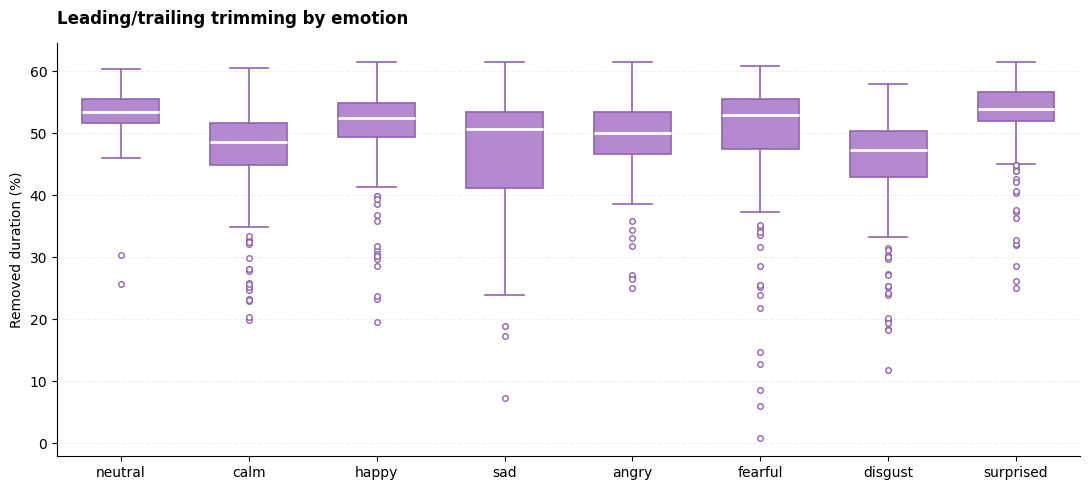

In [ ]:
SILENCE_PATH = OUTPUT_DIR / 'ravdess_trimming_analysis.csv'

if SILENCE_PATH.exists():
    silence_df = pd.read_csv(SILENCE_PATH)
else:
    rows = []
    for row in tqdm(metadata.itertuples(index=False), total=len(metadata), desc='Measuring trimmed duration'):
        y, sr = librosa.load(EXTRACT_DIR / row.relative_path, sr=TARGET_SR, mono=True)
        trimmed, _ = librosa.effects.trim(y, top_db=30)
        rows.append({
            'relative_path': row.relative_path,
            'emotion': row.emotion,
            'actor_id': row.actor_id,
            'original_sec': len(y) / sr,
            'trimmed_sec': len(trimmed) / sr,
            'removed_pct': 100 * (1 - len(trimmed) / len(y)),
        })
    silence_df = pd.DataFrame(rows)
    silence_df.to_csv(SILENCE_PATH, index=False)

assert len(silence_df) == 1440 and silence_df.relative_path.is_unique
assert set(silence_df.relative_path) == set(metadata.relative_path)
EMOTIONS = ['neutral', 'calm', 'happy', 'sad', 'angry', 'fearful', 'disgust', 'surprised']
display(silence_df.groupby('emotion')['removed_pct'].agg(['median','mean','std']).reindex(EMOTIONS).round(2))

fig, ax = plt.subplots(figsize=(11, 5))

sns.boxplot(
    data=silence_df,
    x="emotion",
    y="removed_pct",
    order=EMOTIONS,
    **BOX_STYLE,
    ax=ax
)

style_ax(
    ax,
    "Leading/trailing trimming by emotion"
)

ax.set(xlabel="", ylabel="Removed duration (%)")

plt.tight_layout()
plt.show()

## 5. Acoustic feature distributions

Analyze representative prosodic/spectral features across all recordings. These are descriptive distributions, not out-of-sample prediction scores. Pitch for unvoiced recordings is excluded from the visualization; the ML matrix still contains the finite encoding.

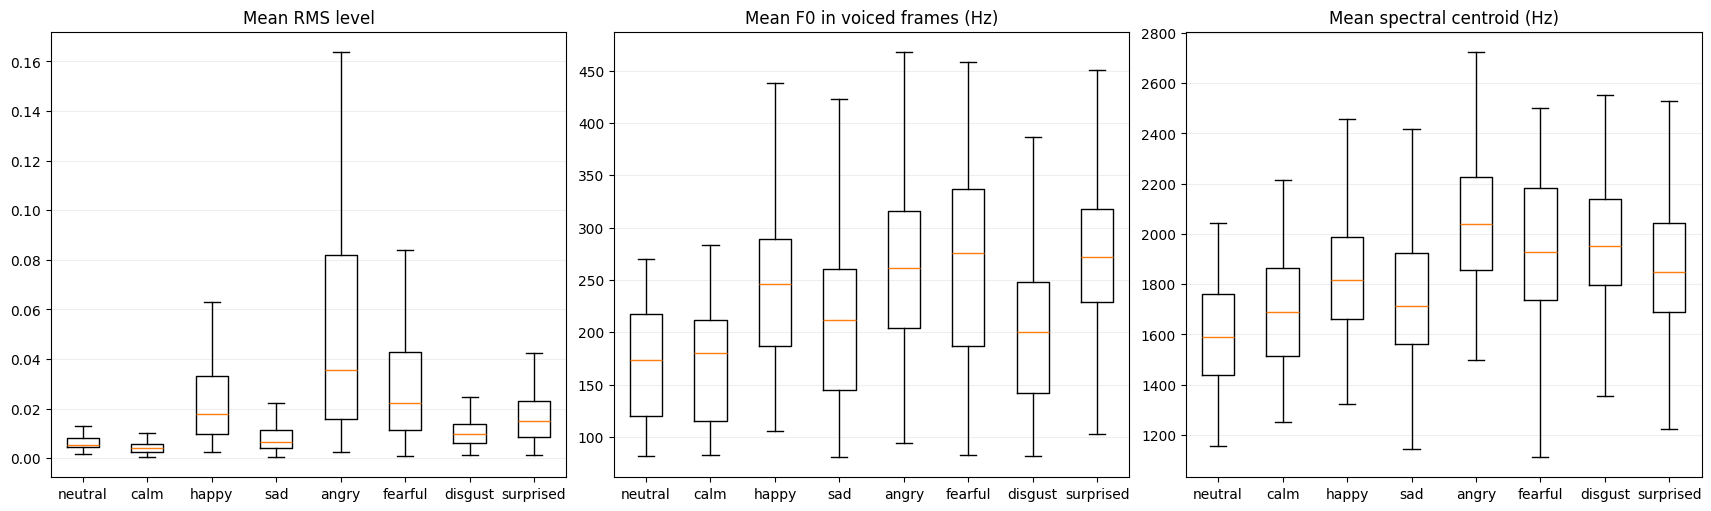

In [ ]:
plot_df = features_df.copy()
plot_df.loc[plot_df.voiced_ratio == 0, 'f0_hz_mean'] = np.nan
features_to_plot = {
    'rms_mean': 'Mean RMS level',
    'f0_hz_mean': 'Mean F0 in voiced frames (Hz)',
    'spectral_centroid_mean': 'Mean spectral centroid (Hz)'
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
for ax, (column, title) in zip(axes, features_to_plot.items()):
    ax.boxplot([plot_df.loc[plot_df.emotion == e, column].dropna() for e in EMOTIONS],
               tick_labels=EMOTIONS, showfliers=False)
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=0)
    ax.grid(axis='y', alpha=.2)
fig.savefig(FIGURES_DIR / 'feature_distributions.png', dpi=170)
plt.show()

## 6. MFCC and feature relationships

MFCC summarizes the spectral envelope on a perceptual (Mel) scale. The heatmap below standardizes columns **only for exploratory visualization** using full-dataset statistics. This is **not** used to train a model (which would leak validation/test information). The feature correlation plot is also descriptive, not causal importance.

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list(
    "blue_lavender",
    ["#2A52BE", "#FAF9FC", "#B57EDC"]
)

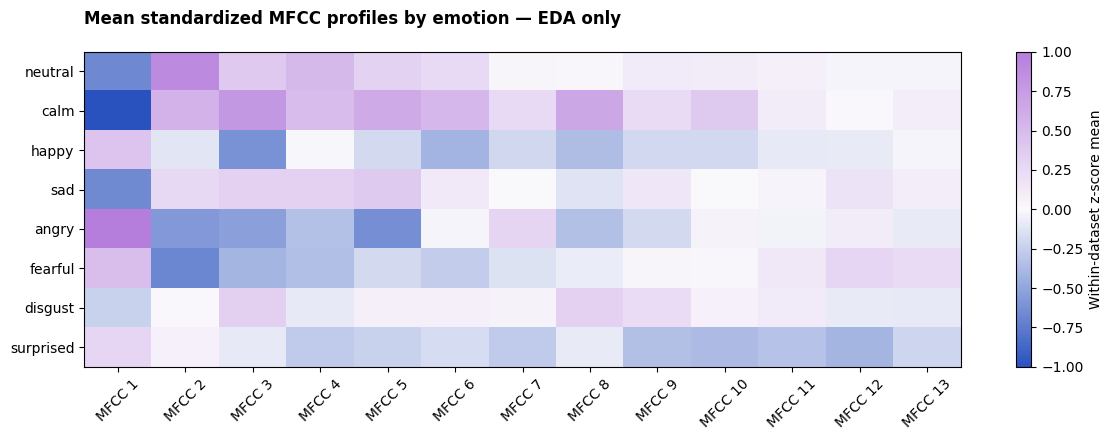

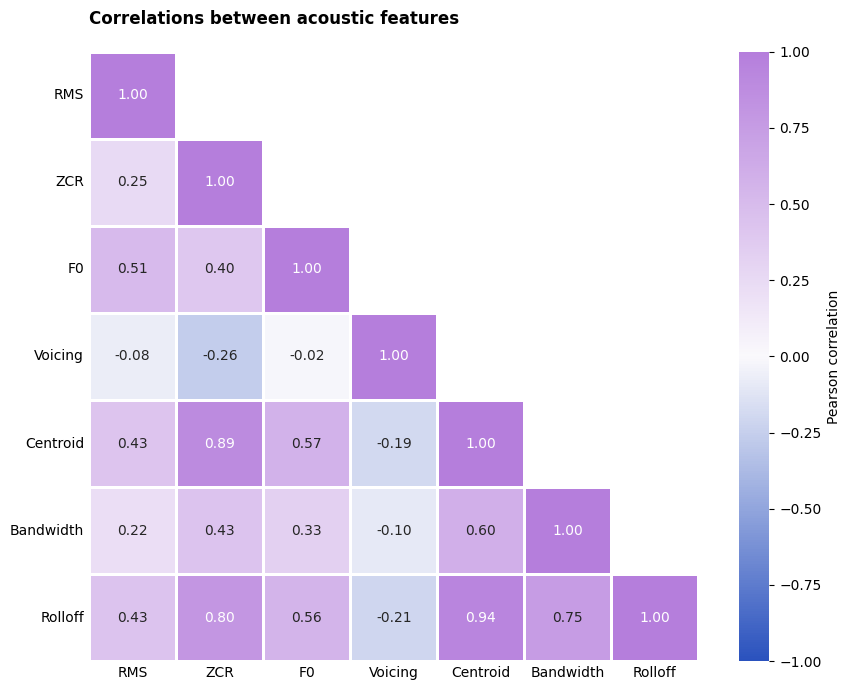

In [ ]:
mfcc_mean_cols = [f'mfcc_{i:02d}_mean' for i in range(1, 14)]
values = features_df[mfcc_mean_cols]
scaled_for_plot = (values - values.mean()) / values.std().replace(0, 1)
profiles = scaled_for_plot.groupby(features_df.emotion).mean().reindex(EMOTIONS)

fig, ax = plt.subplots(figsize=(12, 4.5))
im = ax.imshow(profiles, cmap=cmap, aspect='auto', vmin=-1, vmax=1)
ax.set_yticks(range(len(EMOTIONS)), EMOTIONS)
ax.set_xticks(range(13), [f'MFCC {i}' for i in range(1,14)], rotation=45)

ax.set_title(
    "Mean standardized MFCC profiles by emotion — EDA only",
    fontweight="bold", loc="left", pad=20
)
fig.colorbar(im, ax=ax, label='Within-dataset z-score mean')
plt.tight_layout()
fig.savefig(FIGURES_DIR / 'mfcc_profiles.png', dpi=170)
plt.show()

labels = [
    "RMS", "ZCR", "F0", "Voicing",
    "Centroid", "Bandwidth", "Rolloff"
]

# Match each heatmap label to its exact acoustic feature column.
correlation_columns = {
    "RMS": "rms_mean",
    "ZCR": "zcr_mean",
    "F0": "f0_hz_mean",
    "Voicing": "voiced_ratio",
    "Centroid": "spectral_centroid_mean",
    "Bandwidth": "spectral_bandwidth_mean",
    "Rolloff": "spectral_rolloff_mean",
}

missing = [col for col in correlation_columns.values() if col not in features_df.columns]
if missing:
    raise KeyError(f"Missing acoustic features for correlation plot: {missing}")

corr_df = features_df[list(correlation_columns.values())].copy()
corr_df.columns = list(correlation_columns.keys())
correlation = corr_df.corr()
if correlation.shape != (7, 7) or correlation.isna().any().any():
    raise ValueError("The correlation matrix must be 7x7 and contain no NaNs")
mask = np.triu(np.ones_like(correlation, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    correlation,
    mask=mask,
    cmap=cmap,
    center=0, vmin=-1, vmax=1,
    annot=True, fmt=".2f",
    xticklabels=correlation.columns, yticklabels=correlation.index,
    linewidths=1, linecolor="white",
    square=True,
    cbar_kws={"label": "Pearson correlation"},
    ax=ax
)

ax.set_title(
    "Correlations between acoustic features",
    fontweight="bold", loc="left", pad=20
)
ax.tick_params(axis="both", length=0, labelrotation=0)
plt.tight_layout()
plt.show()

## 7. Output and limitations

- **ML input**: `data/processed/ravdess_features.csv` (39 acoustic features plus metadata).
- **Dataset-level preprocessing diagnostic**: `data/processed/ravdess_trimming_analysis.csv`.
- **Figures**: `results/figures/03_features`.
- Trimming is **not proven beneficial** by its effect on duration; `05` compares trimmed/untrimmed features on the same actor-disjoint validation split.
- Mean and standard deviation ignore temporal dynamics; pitch estimates may be unreliable for some recordings.
- Dataset-wide descriptive statistics here do not use model fitting. The actor-disjoint split and grouped CV are in `04`.

## 8. V2 research design — dynamics × preprocessing

**Question.** Do temporal acoustic features and less aggressive trimming improve speech emotion recognition for **unseen speakers**?

We keep the original `ravdess_features.csv` intact and add a **factorial feature table** for each preprocessing setting:

| Setting | `top_db` | Extraction | Feature sets |
|---|---:|---|---|
| `trim30` | 30 | Existing baseline reused | 39 static / 120 enriched |
| `trim50` | 50 | Re-extract audio | 39 static / 120 enriched |
| `no_trim` | None | Re-extract audio | 39 static / 120 enriched |

The extra 81 features are **78 Delta/Delta-Delta MFCC summary statistics** (13 coefficients × 2 derivatives × 3 statistics), and **3 RMS frame-change statistics**. Deltas are framewise derivatives, but pooling still discards temporal order: this is an enriched *fixed-size* representation, not sequence modelling.

**Important:** `top_db=50` is generally **less** aggressive than `top_db=30` for `librosa.effects.trim`. Trimming results are diagnostics; choose a setting using **train/validation only** in notebook 04. Do not pick a setting from final test scores.

**Runtime:** the new 50 dB and untrimmed conditions re-run pYIN and can be comparatively slow on Colab. All outputs have resumable per-condition checkpoints.

In [ ]:
# V2 configuration — output names encode the exact extraction version.
V2_VERSION = 'v2_delta_rmsdiff_20261104'
TRIM_SETTINGS = {'trim30': 30, 'trim50': 50, 'no_trim': None}
V2_PREFIX = f'ravdess_{V2_VERSION}'
V2_FEATURE_DIR = OUTPUT_DIR / V2_PREFIX
V2_FEATURE_DIR.mkdir(parents=True, exist_ok=True)

STATIC_COLUMNS = list(feature_columns)  # Exactly the 39 original ML columns.
METADATA_COLUMNS = list(metadata.columns)
assert len(STATIC_COLUMNS) == 39 and len(set(STATIC_COLUMNS)) == 39
assert metadata.relative_path.is_unique and features_df.relative_path.is_unique
assert set(metadata.relative_path) == set(features_df.relative_path)

# Deterministic original file lookup; avoids repeated merges and preserves keys.
BASELINE_BY_PATH = features_df.set_index('relative_path')[STATIC_COLUMNS]
print('V2 folder:', V2_FEATURE_DIR)
print('Original baseline CSV preserved:', FEATURES_PATH)

V2 folder: /content/drive/MyDrive/speech-emotion-recognition-project-d/data/processed/ravdess_v2_delta_rmsdiff_20261104
Original baseline CSV preserved: /content/drive/MyDrive/speech-emotion-recognition-project-d/data/processed/ravdess_features.csv


## 9. Dynamic MFCC and energy derivatives

Compute first and second temporal derivatives before pooling. `mean(abs)`, standard deviation and 90th percentile of absolute derivatives retain **magnitude and variability**, avoiding cancellation of signed positive/negative changes. RMS change statistics provide a small energy dynamics signal. All computations use the same 16 kHz / FFT / hop configuration as the original baseline.

In [ ]:
def dynamic_feature_names():
    names = []
    for order in ('delta', 'delta2'):
        for i in range(1, N_MFCC + 1):
            for stat in ('abs_mean', 'std', 'abs_p90'):
                names.append(f'mfcc_{order}_{i:02d}_{stat}')
    names += ['rms_diff_abs_mean', 'rms_diff_std', 'rms_diff_abs_p90']
    return names

DYNAMIC_COLUMNS = dynamic_feature_names()
assert len(DYNAMIC_COLUMNS) == 81 and len(set(DYNAMIC_COLUMNS)) == 81
assert not (set(DYNAMIC_COLUMNS) & set(STATIC_COLUMNS))


def extract_dynamic_features(file_path, top_db=30):
    y, sr = librosa.load(str(file_path), sr=TARGET_SR, mono=True)
    if top_db is not None:
        y, _ = librosa.effects.trim(y, top_db=top_db)
    if not len(y) or np.max(np.abs(y)) < 1e-6:
        raise ValueError(f'Empty or silent recording: {file_path}')

    mfcc = librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=N_MFCC, n_fft=N_FFT, hop_length=HOP_LENGTH
    )
    if mfcc.shape[1] < 9:
        raise ValueError(f'Too few frames for Delta MFCC: {file_path}')
    result = {}
    for name, order in [('delta', 1), ('delta2', 2)]:
        values = librosa.feature.delta(mfcc, order=order, width=9)
        for i, series in enumerate(values, start=1):
            result[f'mfcc_{name}_{i:02d}_abs_mean'] = float(np.mean(np.abs(series)))
            result[f'mfcc_{name}_{i:02d}_std'] = float(np.std(series))
            result[f'mfcc_{name}_{i:02d}_abs_p90'] = float(np.percentile(np.abs(series), 90))

    rms = librosa.feature.rms(y=y, frame_length=N_FFT, hop_length=HOP_LENGTH)[0]
    rms_diff = np.diff(rms)
    if not len(rms_diff):
        raise ValueError(f'Too few RMS frames: {file_path}')
    result['rms_diff_abs_mean'] = float(np.mean(np.abs(rms_diff)))
    result['rms_diff_std'] = float(np.std(rms_diff))
    result['rms_diff_abs_p90'] = float(np.percentile(np.abs(rms_diff), 90))
    assert list(result) == DYNAMIC_COLUMNS
    assert np.isfinite(list(result.values())).all(), file_path
    return result

# Validate one sample, without rewriting existing CSV files.
example_dynamic = extract_dynamic_features(audio_files[0], top_db=30)
print('Original static features:', len(STATIC_COLUMNS))
print('Additional dynamic features:', len(example_dynamic))
print('Enriched feature count:', len(STATIC_COLUMNS) + len(example_dynamic))
display(pd.Series(example_dynamic).head(8).to_frame('sample value'))

Original static features: 39
Additional dynamic features: 81
Enriched feature count: 120


,sample value
mfcc_delta_01_abs_mean,13.865309
mfcc_delta_01_std,18.843716
mfcc_delta_01_abs_p90,21.364002
mfcc_delta_02_abs_mean,6.400518
mfcc_delta_02_std,7.830130
mfcc_delta_02_abs_p90,11.689282
mfcc_delta_03_abs_mean,4.190132
mfcc_delta_03_std,5.445777


## 10. Export versioned feature tables (resumable)

Each mode creates two datasets, both with the exact same 1,440 metadata rows and feature ordering. For `trim30`, the original 39 static values are reused verbatim rather than recomputing pYIN. Checkpoints are specific to the setting and extraction version. A partial checkpoint is **never** interpreted as complete data.

**Reproduction:** If you change feature definitions or spectral parameters, update `V2_VERSION` before running; otherwise valid-but-stale results may be reused.

In [ ]:
def _write_checkpoint(records, path):
    # Atomic replacement: avoids truncated CSV if a runtime interrupts a write.
    temp_path = path.with_suffix('.tmp')
    pd.DataFrame(records).to_csv(temp_path, index=False)
    temp_path.replace(path)


def validate_feature_table(df, expected_feature_cols, *, full):
    expected_cols = METADATA_COLUMNS + list(expected_feature_cols)
    assert df.columns.tolist() == expected_cols, 'Feature schema mismatch; change V2_VERSION.'
    assert df.relative_path.is_unique, 'Duplicate recording keys.'
    assert set(df.relative_path).issubset(set(metadata.relative_path))
    if full:
        assert len(df) == len(metadata) == 1440
        assert set(df.relative_path) == set(metadata.relative_path)
    assert np.isfinite(df[expected_feature_cols].to_numpy(dtype=float)).all()


def run_v2_mode(mode, top_db):
    enriched_path = V2_FEATURE_DIR / f'features_{mode}_enriched.csv'
    static_path = V2_FEATURE_DIR / f'features_{mode}_static.csv'
    checkpoint_path = V2_FEATURE_DIR / f'features_{mode}_checkpoint.csv'
    expected = STATIC_COLUMNS + DYNAMIC_COLUMNS

    if enriched_path.is_file() and static_path.is_file():
        enriched = pd.read_csv(enriched_path)
        static = pd.read_csv(static_path)
        validate_feature_table(enriched, expected, full=True)
        validate_feature_table(static, STATIC_COLUMNS, full=True)
        print(mode, ': reused completed CSVs')
        return enriched

    if checkpoint_path.is_file():
        partial = pd.read_csv(checkpoint_path)
        validate_feature_table(partial, expected, full=False)
        records = partial.to_dict('records')
    else:
        records = []
    completed = {r['relative_path'] for r in records}

    for row in tqdm(metadata.to_dict('records'), desc=f'V2 {mode}', total=len(metadata)):
        key = row['relative_path']
        if key in completed:
            continue
        file_path = EXTRACT_DIR / key
        if mode == 'trim30':
            static_values = BASELINE_BY_PATH.loc[key].to_dict()
        else:
            static_values = extract_features(file_path, top_db=top_db)
        dynamic_values = extract_dynamic_features(file_path, top_db=top_db)
        records.append({**row, **static_values, **dynamic_values})
        completed.add(key)
        if len(records) % 25 == 0:
            _write_checkpoint(records, checkpoint_path)

    enriched = pd.DataFrame(records)[METADATA_COLUMNS + expected]
    enriched = enriched.sort_values('relative_path').reset_index(drop=True)
    validate_feature_table(enriched, expected, full=True)
    static = enriched[METADATA_COLUMNS + STATIC_COLUMNS].copy()
    validate_feature_table(static, STATIC_COLUMNS, full=True)
    _write_checkpoint(enriched.to_dict('records'), enriched_path)
    _write_checkpoint(static.to_dict('records'), static_path)
    if checkpoint_path.exists():
        checkpoint_path.unlink()
    print(f'{mode}: static={static.shape}, enriched={enriched.shape}')
    return enriched

# Optional: set to ['trim30'] for a quick first run; complete all modes for ablation.
MODES_TO_RUN = ['trim30', 'trim50', 'no_trim']
feature_tables_v2 = {
    mode: run_v2_mode(mode, TRIM_SETTINGS[mode]) for mode in MODES_TO_RUN
}

# Baseline invariance check: exact 39 features from existing trim30 output.
if 'trim30' in feature_tables_v2:
    original = features_df.sort_values('relative_path').reset_index(drop=True)
    reproduced = feature_tables_v2['trim30']
    np.testing.assert_allclose(
      reproduced[STATIC_COLUMNS].to_numpy(dtype=float),
      original[STATIC_COLUMNS].to_numpy(dtype=float),
      rtol=1e-12,
      atol=1e-10
    )
    print('Verified: trim30 static features match within numerical tolerance')

trim30 : reused completed CSVs
trim50 : reused completed CSVs
no_trim : reused completed CSVs
Verified: trim30 static features match within numerical tolerance


## 11. Trimming sensitivity diagnostics and downstream hand-off

Compare removed duration for each threshold on the same recordings. These percentages do not establish classification benefit. In Notebook 04, evaluate **static vs enriched**, holding the mode fixed, and **trimming modes**, holding the representation fixed. Retain the original actor-disjoint train/validation/test split and perform hyperparameter tuning using train/grouped CV only. Do not fit scalers or feature selectors in this notebook.

Trim comparison:   0%|          | 0/1440 [00:00<?, ?it/s]

,mean,median,std
trim30,49.10,51.19,8.40
trim50,30.03,33.85,17.06
no_trim,0.00,0.00,0.00


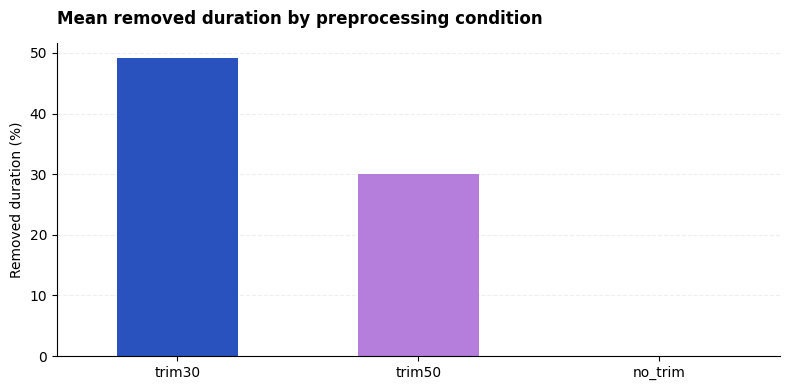

V2 ML inputs:
  trim30   | static   | /content/drive/MyDrive/speech-emotion-recognition-project-d/data/processed/ravdess_v2_delta_rmsdiff_20261104/features_trim30_static.csv | exists=True
  trim30   | enriched | /content/drive/MyDrive/speech-emotion-recognition-project-d/data/processed/ravdess_v2_delta_rmsdiff_20261104/features_trim30_enriched.csv | exists=True
  trim50   | static   | /content/drive/MyDrive/speech-emotion-recognition-project-d/data/processed/ravdess_v2_delta_rmsdiff_20261104/features_trim50_static.csv | exists=True
  trim50   | enriched | /content/drive/MyDrive/speech-emotion-recognition-project-d/data/processed/ravdess_v2_delta_rmsdiff_20261104/features_trim50_enriched.csv | exists=True
  no_trim  | static   | /content/drive/MyDrive/speech-emotion-recognition-project-d/data/processed/ravdess_v2_delta_rmsdiff_20261104/features_no_trim_static.csv | exists=True
  no_trim  | enriched | /content/drive/MyDrive/speech-emotion-recognition-project-d/data/processed/ravdess_v2_d

In [ ]:
TRIM_DIAGNOSTICS_PATH = V2_FEATURE_DIR / 'trimming_comparison.csv'
if TRIM_DIAGNOSTICS_PATH.exists():
    trim_compare = pd.read_csv(TRIM_DIAGNOSTICS_PATH)
    assert len(trim_compare) == 1440 and trim_compare.relative_path.is_unique
    assert set(trim_compare.relative_path) == set(metadata.relative_path)
else:
    records = []
    for row in tqdm(metadata.itertuples(index=False), total=len(metadata), desc='Trim comparison'):
        y, sr = librosa.load(EXTRACT_DIR / row.relative_path, sr=TARGET_SR, mono=True)
        entry = {'relative_path': row.relative_path, 'emotion': row.emotion,
                 'actor_id': row.actor_id, 'original_sec': len(y) / sr}
        for mode, db in TRIM_SETTINGS.items():
            yy = y if db is None else librosa.effects.trim(y, top_db=db)[0]
            entry[f'removed_pct_{mode}'] = 100 * (1 - len(yy) / len(y))
        records.append(entry)
    trim_compare = pd.DataFrame(records)
    trim_compare.to_csv(TRIM_DIAGNOSTICS_PATH, index=False)

summary = trim_compare[[f'removed_pct_{mode}' for mode in TRIM_SETTINGS]].agg(['mean', 'median', 'std']).T
summary.index = [key.replace('removed_pct_', '') for key in summary.index]
display(summary.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
summary['mean'].plot(kind='bar', ax=ax, color=[BLUE, PURPLE, DARK_PURPLE])
style_ax(ax, 'Mean removed duration by preprocessing condition')
ax.set(xlabel='', ylabel='Removed duration (%)')
plt.tight_layout()
plt.show()

print('V2 ML inputs:')
for mode in TRIM_SETTINGS:
    for representation in ['static', 'enriched']:
        path = V2_FEATURE_DIR / f'features_{mode}_{representation}.csv'
        print(f'  {mode:8s} | {representation:8s} | {path} | exists={path.is_file()}')
print('Next: update notebook 04 to evaluate these six tables without test-set selection.')